In [ ]:
import nanonis_spm
import numpy as np
from os.path import join
import socket

from prisma.experiment import init_nanonis_instance, SpectroscopySeriesSweep
from prisma.physics_models.python import Ibeem_vector

In [ ]:
np.random.seed(0)

In [ ]:
save_dir = 'Beem_Data\\Nanonis_Test_9'

# Test

In [ ]:
nanonis_instance = init_nanonis_instance()
nanonis_instance.returnDebugInfo(1)

In [ ]:
series_ct_test = 1
sample_ct = 33
x0 = 1.25
xf = 0.4

In [ ]:
spectr_series_test = SpectroscopySeriesSweep(nanonis_instance, series_ct_test, sample_ct, x0, xf)

In [ ]:
spectr_series_test.run()

In [ ]:
spectr_series_test.t_n_series_np = -1 * spectr_series_test.t_n_series_np

In [ ]:
spectr_series_test.plot_spectrum_i(0)

In [ ]:
p0_cf = [.04, .8, 1.]

In [ ]:
model_f = Ibeem_vector

In [ ]:
spectr_series_test.curve_fit_spectra(model_f, p0_cf)

In [ ]:
spectr_series_test.popt_np

array([4.12057000e-02, 8.50363616e-01, 7.35050247e-06])

In [ ]:
spectr_series_test.pcov_np

array([[4.93228697e-08, 8.32261647e-07, 4.13799053e-12],
       [8.32261647e-07, 6.34486012e-05, 1.38913243e-09],
       [4.13799053e-12, 1.38913243e-09, 4.47583704e-14]])

In [ ]:
np.sqrt(spectr_series_test.pcov_np[0, 1, 1])

np.float64(0.007965463022797447)

In [ ]:
spectr_series_test.plot_spectrum_i(0, f_cf=model_f)

# Experiment

In [ ]:
series_ct_exp = 100

In [ ]:
spectr_series_exp = SpectroscopySeriesSweep(nanonis_instance, series_ct_exp, sample_ct, x0, xf)

In [ ]:
spectr_series_exp.run()

In [ ]:
spectr_series_exp.t_n_series_np = -1 * spectr_series_exp.t_n_series_np

In [ ]:
spectr_series_exp.plot_spectra()

In [ ]:
spectr_series_exp.curve_fit_spectra(model_f, p0_cf)

In [ ]:
np.mean(spectr_series_exp.popt_np, axis=0)

array([3.54596570e-02, 8.73992273e-01, 1.19475204e-05])

In [ ]:
spectr_series_exp.popt_np[:, 1]

array([0.8656006 , 0.86173517, 0.8584708 , 0.85650365, 0.84360386,
       0.84338874, 0.84966252, 0.83840192, 0.86672362, 0.86873758,
       0.87105167, 0.86931943, 0.84826773, 0.86953963, 0.82850084,
       0.84751463, 0.85208853, 0.83589042, 0.86301417, 0.87198258,
       0.8591799 , 0.85241121, 0.84506204, 0.84971135, 0.84793246,
       0.84295671, 0.86851266, 0.840244  , 0.85175746, 0.85293437,
       0.85672821, 0.79989647, 0.88192075, 0.93147067, 0.85342425,
       0.8792526 , 0.86708963, 0.85805496, 0.87156269, 0.87606668,
       0.87430322, 0.90159155, 0.8989462 , 0.93527125, 0.91881847,
       0.92559562, 0.89624487, 0.91278535, 0.86411177, 0.90949092,
       0.87485013, 0.88262325, 0.90504163, 0.88393805, 0.90915978,
       0.8747859 , 0.89573512, 0.88931544, 0.90974229, 0.89855635,
       0.90172579, 0.90372091, 0.91212535, 0.88809661, 0.88614064,
       0.8553304 , 0.91014988, 0.8983935 , 0.90190694, 0.91494235,
       0.89924608, 0.87011905, 0.87215413, 0.88504659, 0.86471

In [ ]:
np.std(spectr_series_exp.popt_np, axis=0)

array([1.18193029e-03, 2.50906684e-02, 3.34274980e-06])

In [ ]:
np.mean(np.sqrt(spectr_series_exp.pcov_np), axis=0)

array([[3.55921328e-04, 1.16480205e-03, 3.61290885e-06],
       [1.16480205e-03, 8.49430727e-03, 5.21391177e-05],
       [3.61290885e-06, 5.21391177e-05, 3.94222052e-07]])

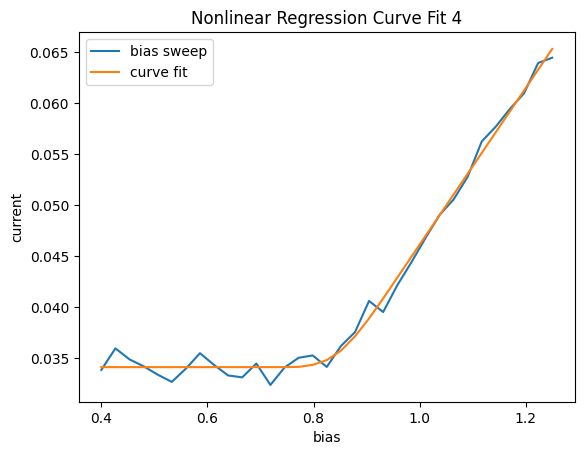

In [ ]:
spectr_series_exp.plot_spectrum_i(0, f_cf=model_f)

In [ ]:
spectr_series_exp.save_spectroscopy_series(save_dir)

In [ ]:
nanonis_instance.close()